In [1]:
import sqlite3
import pandas as pd

print("SQLite and Pandas are ready!")

SQLite and Pandas are ready!


In [2]:
conn = sqlite3.connect("sales_analysis.db")

print("Database created successfully!")

Database created successfully!


In [3]:
sales_data = {
    "Product": [
        "AirPods Pro 2",
        "Smart Watch T900",
        "Anker Cable",
        "AirPods Pro 4",
        "Smart Watch T1000",
        "Smart Watch T2000",
        "AirPods Pro 2",
        "Anker Cable",
        "AirPods Pro 4",
        "Smart Watch T900"
    ],
    "Category": [
        "AirPods",
        "Smart Watches",
        "Cables",
        "AirPods",
        "Smart Watches",
        "Smart Watches",
        "AirPods",
        "Cables",
        "AirPods",
        "Smart Watches"
    ],
    "Price": [
        159, 159, 10, 200, 159,
        159, 159, 10, 200, 159
    ],
    "Quantity": [
        8, 5, 15, 6, 4,
        3, 7, 20, 5, 6
    ],
    "Month": [
        "January",
        "January",
        "February",
        "February",
        "March",
        "March",
        "April",
        "April",
        "April",
        "May"
    ]
}

sales_df = pd.DataFrame(sales_data)

sales_df["Total_Sales"] = sales_df["Price"] * sales_df["Quantity"]

sales_df

,Product,Category,Price,Quantity,Month,Total_Sales
0,AirPods Pro 2,AirPods,159,8,January,1272
1,Smart Watch T900,Smart Watches,159,5,January,795
2,Anker Cable,Cables,10,15,February,150
3,AirPods Pro 4,AirPods,200,6,February,1200
4,Smart Watch T1000,Smart Watches,159,4,March,636
5,Smart Watch T2000,Smart Watches,159,3,March,477
6,AirPods Pro 2,AirPods,159,7,April,1113
7,Anker Cable,Cables,10,20,April,200
8,AirPods Pro 4,AirPods,200,5,April,1000
9,Smart Watch T900,Smart Watches,159,6,May,954


In [4]:
sales_df.to_sql(
    "sales",
    conn,
    if_exists="replace",
    index=False
)

print("Sales table created successfully!")

Sales table created successfully!


In [5]:
query = """
SELECT SUM(Total_Sales) AS Total_Sales
FROM sales;
"""

result = pd.read_sql_query(query, conn)

result

,Total_Sales
0,7797


In [6]:
query = """
SELECT
    Product,
    SUM(Quantity) AS Total_Quantity,
    SUM(Total_Sales) AS Total_Sales
FROM sales
GROUP BY Product
ORDER BY Total_Sales DESC;
"""

product_sales = pd.read_sql_query(query, conn)

product_sales

,Product,Total_Quantity,Total_Sales
0,AirPods Pro 2,15,2385
1,AirPods Pro 4,11,2200
2,Smart Watch T900,11,1749
3,Smart Watch T1000,4,636
4,Smart Watch T2000,3,477
5,Anker Cable,35,350


In [7]:
query = """
SELECT
    Category,
    SUM(Quantity) AS Total_Quantity,
    SUM(Total_Sales) AS Total_Sales
FROM sales
GROUP BY Category
ORDER BY Total_Sales DESC;
"""

category_sales = pd.read_sql_query(query, conn)

category_sales

,Category,Total_Quantity,Total_Sales
0,AirPods,26,4585
1,Smart Watches,18,2862
2,Cables,35,350


In [8]:
query = """
SELECT
    Month,
    SUM(Quantity) AS Total_Quantity,
    SUM(Total_Sales) AS Total_Sales
FROM sales
GROUP BY Month
ORDER BY Total_Sales DESC;
"""

monthly_sales = pd.read_sql_query(query, conn)

monthly_sales

,Month,Total_Quantity,Total_Sales
0,April,32,2313
1,January,13,2067
2,February,21,1350
3,March,7,1113
4,May,6,954


In [9]:
query = """
SELECT
    Product,
    SUM(Total_Sales) AS Total_Sales
FROM sales
GROUP BY Product
ORDER BY Total_Sales DESC
LIMIT 3;
"""

top_products = pd.read_sql_query(query, conn)

top_products

,Product,Total_Sales
0,AirPods Pro 2,2385
1,AirPods Pro 4,2200
2,Smart Watch T900,1749


In [10]:
conn.close()

print("Database connection closed successfully!")

Database connection closed successfully!


## Business Insights

- SQL queries were used to analyze product, category, and monthly sales performance.
- Product-level analysis helps identify the strongest products.
- Category-level analysis helps the business understand which product groups generate more sales.
- Monthly analysis helps identify stronger sales periods.
- SQL provides an efficient way to extract business insights from structured sales data.

In [11]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("sales_analysis.db")

query = """
SELECT
    Product,
    SUM(Total_Sales) AS Total_Sales
FROM sales
GROUP BY Product
ORDER BY Total_Sales DESC;
"""

product_sales = pd.read_sql_query(query, conn)

product_sales

,Product,Total_Sales
0,AirPods Pro 2,2385
1,AirPods Pro 4,2200
2,Smart Watch T900,1749
3,Smart Watch T1000,636
4,Smart Watch T2000,477
5,Anker Cable,350


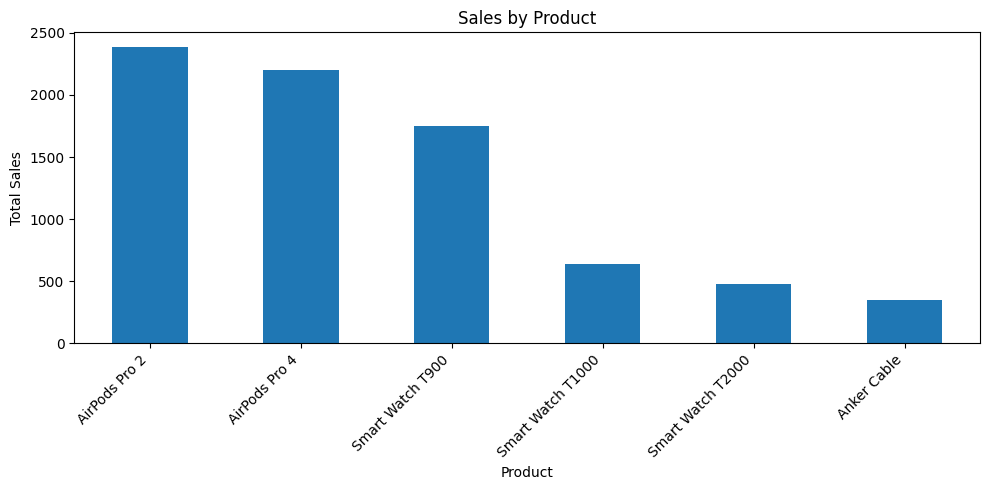

In [12]:
product_sales.plot(
    x="Product",
    y="Total_Sales",
    kind="bar",
    figsize=(10, 5),
    legend=False
)

plt.title("Sales by Product")
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()